# PathSnap — GPS Trajectory Exploratory Data Analysis

This notebook analyzes GPS observations from `data/train/` and `data/student_test/` only. It does not read road-network files, create candidate segments or labels, or train models. The source `.track` observations are preserved; invalid intervals and outliers are reported rather than removed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.gps_eda import (
    GAP_THRESHOLDS_SECONDS,
    analyze_gps_dataset,
    create_representative_maps,
    write_summary_report,
)

DATA_ROOT = PROJECT_ROOT / 'data'
REPORT_ROOT = PROJECT_ROOT / 'reports'
pd.set_option('display.max_columns', 30)
analysis = analyze_gps_dataset(DATA_ROOT)
print(f'Loaded {len(analysis["observations"]):,} GPS rows from {len(analysis["inventory"]):,} trip directories.')

Loaded 227,577 GPS rows from 90 trip directories.


## 1. Dataset Inventory

Trip directories are counted independently from available `.track` files. Missing and empty files remain in the inventory with zero observations; malformed/unreadable tracks are marked and are not silently treated as valid.

In [2]:
display(analysis['split_summary'])
print('Trip inventory: trip_id, dataset_split, gps_point_count')
print(analysis['inventory'][['trip_id', 'dataset_split', 'gps_point_count']].to_string(index=False))
print('\nTrack statuses:')
display(analysis['inventory'].groupby(['dataset_split', 'track_status']).size().rename('trip_count').reset_index())

,dataset_split,trip_directory_count,available_track_files,missing_track_files,empty_track_files,malformed_track_files,total_gps_observations,trips_with_known_point_count,minimum_observations_per_trip,maximum_observations_per_trip,mean_observations_per_trip,median_observations_per_trip,standard_deviation_observations_per_trip,first_quartile_observations_per_trip,third_quartile_observations_per_trip,minimum_observation_trip_ids,maximum_observation_trip_ids
0,train,80,80,0,0,0,208417,80,361.0,19313.0,2605.2125,1529.0,3312.345399,945.75,2792.75,00000026,00000054
1,student_test,10,10,0,0,0,19160,10,262.0,3958.0,1916.0000,1420.0,1335.432348,917.75,2872.00,00000052,00000056


Trip inventory: trip_id, dataset_split, gps_point_count
 trip_id dataset_split  gps_point_count
00000001         train             1315
00000002         train             7243
00000003         train              821
00000004         train             1064
00000005         train             1045
00000006         train             1450
00000008         train             3093
00000010         train             2711
00000011         train             2828
00000012         train             1608
00000013         train             2580
00000014         train              448
00000016         train             1305
00000018         train              379
00000019         train             2354
00000020         train             2353
00000021         train            15783
00000022         train              474
00000024         train              801
00000025         train             1179
00000026         train              361
00000027         train              694
00000028         train  

,dataset_split,track_status,trip_count
0,student_test,valid,10
1,train,valid,80


## 2. GPS Observation Analysis

The distribution comparison uses the known GPS row count for each trip. Short/long trip flags use the 1.5×IQR rule calculated separately within each split; these flags indicate unusual sample counts, not data errors.

,dataset_split,trip_directory_count,total_gps_observations,minimum_observations_per_trip,maximum_observations_per_trip,mean_observations_per_trip,median_observations_per_trip,standard_deviation_observations_per_trip,first_quartile_observations_per_trip,third_quartile_observations_per_trip,minimum_observation_trip_ids,maximum_observation_trip_ids
0,train,80,208417,361.0,19313.0,2605.2125,1529.0,3312.345399,945.75,2792.75,00000026,00000054
1,student_test,10,19160,262.0,3958.0,1916.0000,1420.0,1335.432348,917.75,2872.00,00000052,00000056


Unusually short or long trips by the within-split 1.5×IQR rule:


,trip_id,dataset_split,gps_point_count,outlier_direction,lower_fence,upper_fence
0,00000002,train,7243,long,-1824.75,5563.25
1,00000021,train,15783,long,-1824.75,5563.25
2,00000033,train,5844,long,-1824.75,5563.25
3,00000042,train,7739,long,-1824.75,5563.25
4,00000054,train,19313,long,-1824.75,5563.25
5,00000084,train,16031,long,-1824.75,5563.25
6,00000092,train,7892,long,-1824.75,5563.25
7,00000098,train,5584,long,-1824.75,5563.25


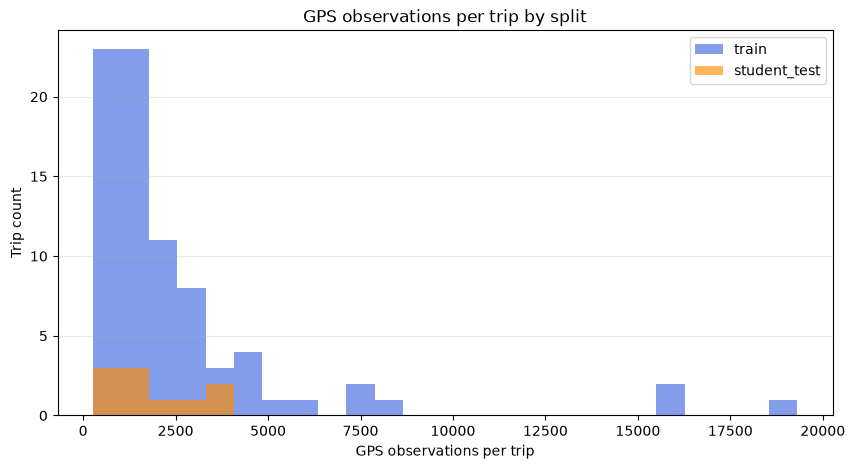

In [3]:
display(analysis['split_summary'][[
    'dataset_split', 'trip_directory_count', 'total_gps_observations',
    'minimum_observations_per_trip', 'maximum_observations_per_trip',
    'mean_observations_per_trip', 'median_observations_per_trip',
    'standard_deviation_observations_per_trip',
    'first_quartile_observations_per_trip', 'third_quartile_observations_per_trip',
    'minimum_observation_trip_ids', 'maximum_observation_trip_ids',
]])
print('Unusually short or long trips by the within-split 1.5×IQR rule:')
display(analysis['trip_count_outliers'])

all_counts = analysis['inventory']['gps_point_count'].dropna()
count_bin_edges = np.histogram_bin_edges(all_counts, bins=25)
fig, ax = plt.subplots(figsize=(10, 5))
for split, color in [('train', 'royalblue'), ('student_test', 'darkorange')]:
    counts = analysis['inventory'].loc[
        (analysis['inventory']['dataset_split'] == split)
        & analysis['inventory']['gps_point_count'].notna(),
        'gps_point_count',
    ]
    ax.hist(counts, bins=count_bin_edges, alpha=0.65, label=split, color=color)
ax.set(title='GPS observations per trip by split', xlabel='GPS observations per trip', ylabel='Trip count')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

## 3. Timestamp Analysis

The source timestamps are numeric seconds. Every consecutive difference is retained, including zero, negative, and long intervals. One-second intervals use a 1 μs tolerance to account for decimal text representation.

Per-trip timestamp and duration summary:
 trip_id dataset_split  gps_point_count  timestamp_value_count  timestamp_invalid_value_count  timestamp_monotonic  duration_seconds  minimum_interval_seconds  maximum_interval_seconds  mean_interval_seconds  median_interval_seconds  one_second_interval_count  zero_interval_count  negative_interval_count  gap_over_5_seconds_count  gap_over_10_seconds_count  gap_over_30_seconds_count  gap_over_60_seconds_count
00000001         train             1315                   1315                              0                 True          1357.000                       1.0                      16.0               1.032725                      1.0                       1289                    0                        0                         1                          1                          0                          0
00000002         train             7243                   7243                              0                 True          8933.156 

,trip_id,dataset_split,maximum_interval_seconds,gap_over_5_seconds_count,gap_over_10_seconds_count,gap_over_30_seconds_count,gap_over_60_seconds_count
72,00000090,train,153064.0,20,6,1,1
61,00000078,train,52810.0,124,25,2,1
55,00000069,train,2658.0,2,2,2,2
16,00000021,train,2161.0,2,2,2,2
8,00000011,train,909.0,1,1,1,1
34,00000042,train,670.0,45,37,22,17
64,00000081,train,536.0,129,86,37,15
18,00000024,train,458.0,4,2,2,2
36,00000044,train,341.0,2,2,2,1
67,00000084,train,312.0,4,4,4,2


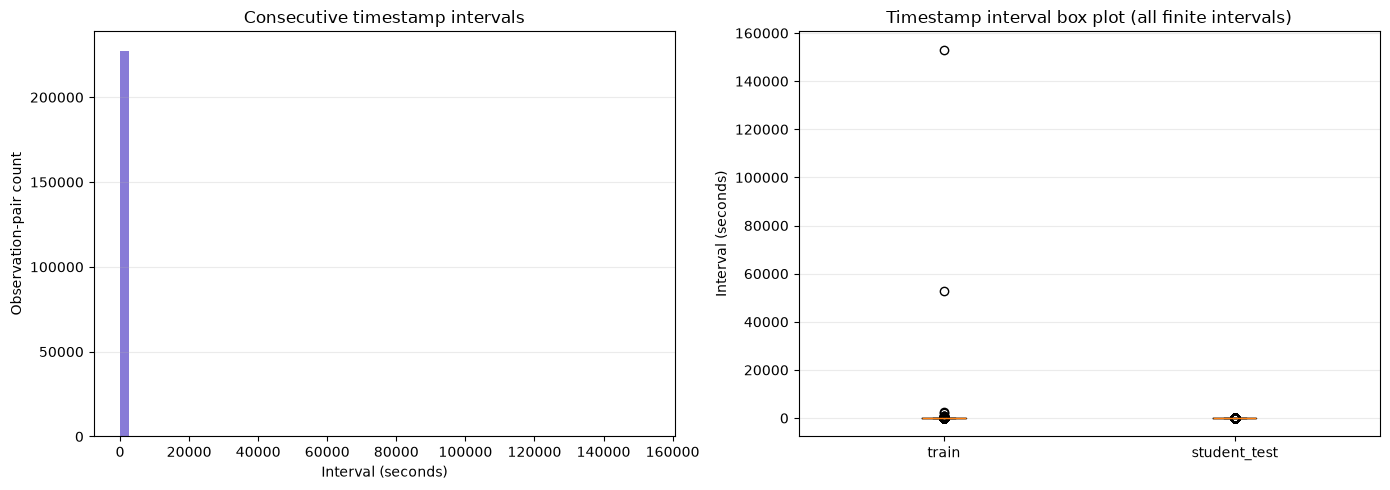

In [4]:
timestamp_columns = [
    'trip_id', 'dataset_split', 'gps_point_count', 'timestamp_value_count',
    'timestamp_invalid_value_count', 'timestamp_monotonic', 'duration_seconds',
    'minimum_interval_seconds', 'maximum_interval_seconds', 'mean_interval_seconds',
    'median_interval_seconds', 'one_second_interval_count', 'zero_interval_count',
    'negative_interval_count',
] + [f'gap_over_{threshold}_seconds_count' for threshold in GAP_THRESHOLDS_SECONDS]
print('Per-trip timestamp and duration summary:')
print(analysis['timestamp_summary'][timestamp_columns].to_string(index=False))

large_gap_columns = [f'gap_over_{threshold}_seconds_count' for threshold in GAP_THRESHOLDS_SECONDS]
large_gap_trips = analysis['timestamp_summary'].loc[
    analysis['timestamp_summary'][large_gap_columns].fillna(0).gt(0).any(axis=1),
    ['trip_id', 'dataset_split', 'maximum_interval_seconds'] + large_gap_columns,
]
print('\nTrips containing gaps above one or more requested thresholds:')
display(large_gap_trips.sort_values('maximum_interval_seconds', ascending=False))

intervals = analysis['intervals']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
finite_intervals = intervals.loc[np.isfinite(intervals['elapsed_seconds']), 'elapsed_seconds']
axes[0].hist(finite_intervals, bins=60, color='slateblue', alpha=0.8)
axes[0].set(title='Consecutive timestamp intervals', xlabel='Interval (seconds)', ylabel='Observation-pair count')
split_intervals = [
    intervals.loc[
        (intervals['dataset_split'] == split) & np.isfinite(intervals['elapsed_seconds']),
        'elapsed_seconds',
    ].to_numpy()
    for split in ['train', 'student_test']
]
axes[1].boxplot(split_intervals, tick_labels=['train', 'student_test'])
axes[1].set(title='Timestamp interval box plot (all finite intervals)', ylabel='Interval (seconds)')
for ax in axes:
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Speed Analysis

Point-to-point distances use the WGS84 geodesic helper in `src/geo.py` and are in metres. Speeds are calculated only for valid endpoint coordinates and positive elapsed seconds. Invalid transitions are retained with a reason; the high-speed review threshold is the greater of 200 km/h and pooled Q3 + 3×IQR. No outliers are removed.

Speed descriptive statistics (m/s):


,count,mean,std,min,25%,50%,75%,max
dataset_split,,,,,,,,
student_test,19150.0,15.421195,8.828872,0.024362,8.410303,14.145606,21.522452,72.986887
train,208337.0,13.708699,10.035019,0.000000,6.523355,11.077854,18.353269,180.594345



Unusually-high-speed review threshold: 200.00 km/h
Per-trip speed summary:
dataset_split  trip_id  gps_point_count  valid_speed_interval_count  invalid_speed_calculation_count  mean_speed_mps  median_speed_mps  maximum_speed_mps  mean_speed_kmh  median_speed_kmh  maximum_speed_kmh  unusually_high_speed_interval_count
        train 00000001             1315                        1314                                0       38.052862         41.381319          72.444519      136.990304        148.972750         260.800267                                  150
        train 00000002             7243                        7242                                0        7.589928          7.068626          37.381828       27.323740         25.447054         134.574581                                    0
        train 00000003              821                         820                                0       10.258118          9.315049          29.219252       36.929226         33.534175     

,dataset_split,trip_id,unusually_high_speed_interval_count,maximum_flagged_speed_kmh
0,train,00000032,615,300.338591
1,train,00000001,150,260.800267
2,train,00000013,105,510.753829
3,train,00000024,11,236.803118
4,train,00000043,7,474.314582
5,train,00000092,4,306.956384
6,train,00000028,4,243.873370
7,train,00000055,4,236.024228
8,train,00000079,3,650.139642
9,train,00000033,3,511.648614



Highest-speed individual transitions (retained, not filtered from analysis):


,dataset_split,trip_id,transition_index,elapsed_seconds,distance_m,speed_mps,speed_kmh
148769,train,00000079,90,1.0,180.594345,180.594345,650.139642
67982,train,00000033,5113,1.0,142.124615,142.124615,511.648614
24299,train,00000013,1132,1.0,141.876064,141.876064,510.753829
148774,train,00000079,95,1.0,133.355569,133.355569,480.080050
87572,train,00000043,1158,1.0,131.754051,131.754051,474.314582
24298,train,00000013,1131,1.0,129.235979,129.235979,465.249526
25174,train,00000013,2007,1.0,114.594480,114.594480,412.540128
24881,train,00000013,1714,1.0,113.208039,113.208039,407.548941
24297,train,00000013,1130,1.0,112.390728,112.390728,404.606622
86858,train,00000043,444,1.0,110.173814,110.173814,396.625730



Invalid speed calculations by reason:


,transition_count
speed_invalid_reason,


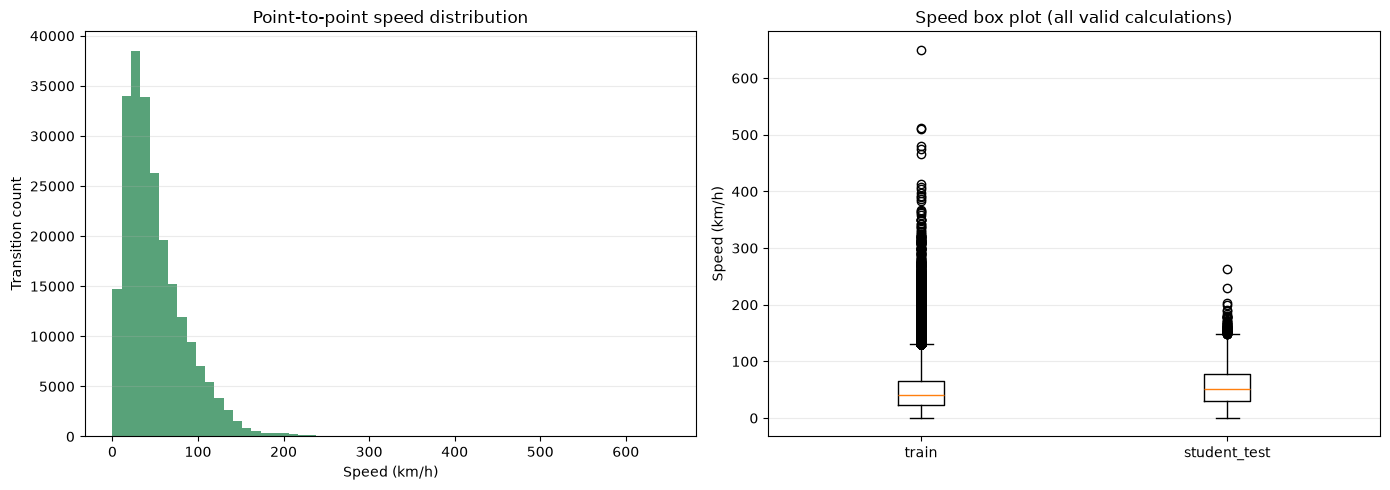

In [5]:
valid_speed_intervals = intervals.loc[intervals['speed_mps'].notna()].copy()
speed_statistics = valid_speed_intervals.groupby('dataset_split')['speed_mps'].describe()
print('Speed descriptive statistics (m/s):')
display(speed_statistics)
print(f"\nUnusually-high-speed review threshold: {analysis['high_speed_threshold_mps'] * 3.6:.2f} km/h")
print('Per-trip speed summary:')
print(analysis['speed_summary'].to_string(index=False))
print('\nTrips with unusually high-speed transitions:')
display(analysis['high_speed_trips'])
print('\nHighest-speed individual transitions (retained, not filtered from analysis):')
display(analysis['high_speed_transitions'][[
    'dataset_split', 'trip_id', 'transition_index', 'elapsed_seconds',
    'distance_m', 'speed_mps', 'speed_kmh',
]].head(20))
print('\nInvalid speed calculations by reason:')
display(intervals.loc[intervals['speed_mps'].isna(), 'speed_invalid_reason'].value_counts(dropna=False).rename('transition_count').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(valid_speed_intervals['speed_kmh'], bins=60, color='seagreen', alpha=0.8)
axes[0].set(title='Point-to-point speed distribution', xlabel='Speed (km/h)', ylabel='Transition count')
split_speeds = [
    valid_speed_intervals.loc[valid_speed_intervals['dataset_split'] == split, 'speed_kmh'].to_numpy()
    for split in ['train', 'student_test']
]
axes[1].boxplot(split_speeds, tick_labels=['train', 'student_test'])
axes[1].set(title='Speed box plot (all valid calculations)', ylabel='Speed (km/h)')
for ax in axes:
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Coordinate Analysis

Coordinate summaries use only valid longitude/latitude pairs. Missing values and finite-but-out-of-range coordinates are counted separately. Geographic coverage is an approximate bounding rectangle whose dimensions are calculated geodesically in kilometres; it is not a route length.

,dataset_split,valid_coordinate_count,missing_longitude_values,missing_latitude_values,invalid_coordinate_observations,longitude_min,longitude_max,longitude_mean,longitude_median,latitude_min,latitude_max,latitude_mean,latitude_median
0,all,227577,0,0,0,-100.418538,137.237029,15.455825,12.441444,-34.640291,61.699590,41.466325,49.564169
1,train,208417,0,0,0,-100.418538,137.237029,15.041646,11.049602,-34.640291,61.267258,40.435837,49.280999
2,student_test,19160,0,0,0,-93.424337,77.271115,19.961145,50.809622,42.645529,61.699590,52.675686,55.315124


Approximate geographic coverage by bounding rectangle:


,dataset_split,west_longitude,east_longitude,south_latitude,north_latitude,approximate_width_km,approximate_height_km,approximate_bbox_area_km2
0,all,-100.418538,137.237029,-34.640291,61.699590,19853.495029,10678.140053,2.119984e+08
1,train,-100.418538,137.237029,-34.640291,61.267258,20164.604282,10629.962223,2.143490e+08
2,student_test,-93.424337,77.271115,42.645529,61.699590,11545.613746,2120.110337,2.447798e+07


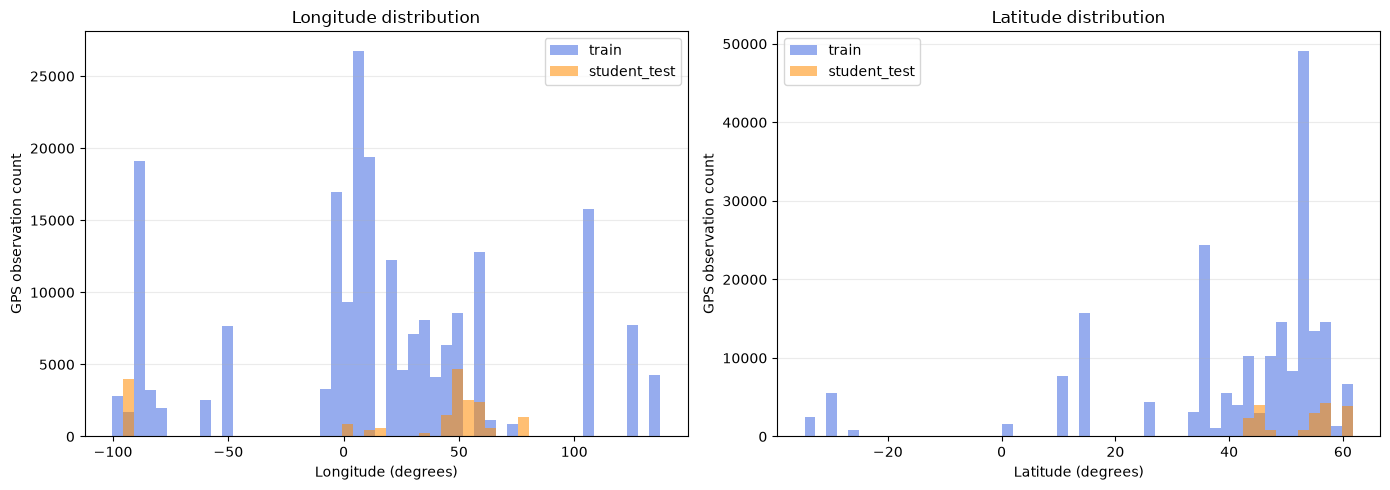

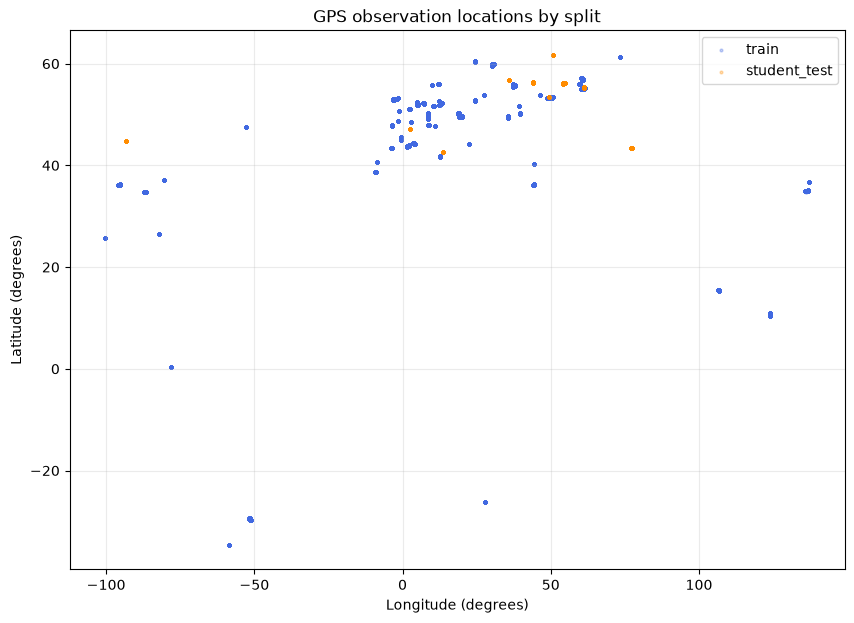

In [6]:
display(analysis['coordinate_summary'])
print('Approximate geographic coverage by bounding rectangle:')
display(analysis['geographic_coverage'])

observations = analysis['observations']
valid_coordinate_mask = (
    np.isfinite(observations['longitude'])
    & np.isfinite(observations['latitude'])
    & observations['longitude'].between(-180, 180)
    & observations['latitude'].between(-90, 90)
)
valid_coordinates = observations.loc[valid_coordinate_mask]
longitude_bin_edges = np.histogram_bin_edges(valid_coordinates['longitude'], bins=50)
latitude_bin_edges = np.histogram_bin_edges(valid_coordinates['latitude'], bins=50)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for split, color in [('train', 'royalblue'), ('student_test', 'darkorange')]:
    points = valid_coordinates.loc[valid_coordinates['dataset_split'] == split]
    axes[0].hist(points['longitude'], bins=longitude_bin_edges, alpha=0.55, label=split, color=color)
    axes[1].hist(points['latitude'], bins=latitude_bin_edges, alpha=0.55, label=split, color=color)
axes[0].set(title='Longitude distribution', xlabel='Longitude (degrees)', ylabel='GPS observation count')
axes[1].set(title='Latitude distribution', xlabel='Latitude (degrees)', ylabel='GPS observation count')
for ax in axes:
    ax.legend()
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
for split, color in [('train', 'royalblue'), ('student_test', 'darkorange')]:
    points = valid_coordinates.loc[valid_coordinates['dataset_split'] == split]
    ax.scatter(points['longitude'], points['latitude'], s=4, alpha=0.3, label=split, color=color)
ax.set(title='GPS observation locations by split', xlabel='Longitude (degrees)', ylabel='Latitude (degrees)')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 6. GPS Trajectory Visualisation

Representative trips are selected by GPS point count (short, median-sized, and long), with a student-test median trip added when distinct. These Folium maps use `.track` observations only, sort points by timestamp with stable ordering for ties, mark endpoints, and fit bounds to the mapped coordinates.

In [7]:
map_records = create_representative_maps(analysis, REPORT_ROOT / 'maps')
display(map_records)
for row in map_records.itertuples(index=False):
    relative_map_path = Path(row.map_path).relative_to(PROJECT_ROOT)
    print(f'{row.selection}: {row.trip_id} ({row.dataset_split}) — {relative_map_path.as_posix()}')

,selection,dataset_split,trip_id,gps_point_count,map_path,mapped_point_count
0,short,student_test,00000052,262,C:\Users\Yashita Anand\OneDrive\Desktop\Pathsn...,262
1,medium,train,00000083,1507,C:\Users\Yashita Anand\OneDrive\Desktop\Pathsn...,1507
2,long,train,00000054,19313,C:\Users\Yashita Anand\OneDrive\Desktop\Pathsn...,19313
3,student-test medium,student_test,00000076,1486,C:\Users\Yashita Anand\OneDrive\Desktop\Pathsn...,1486


short: 00000052 (student_test) — reports/maps/trip_00000052.html
medium: 00000083 (train) — reports/maps/trip_00000083.html
long: 00000054 (train) — reports/maps/trip_00000054.html
student-test medium: 00000076 (student_test) — reports/maps/trip_00000076.html


## 7. GPS Data Quality Analysis

Issue counts are grouped by trip and issue type. Timestamp gaps and high speeds are reported, not automatically removed. For malformed tracks, raw nonblank lines are retained as rows when they can be read; missing/unparseable values remain unavailable for calculations.

In [8]:
quality_issues = analysis['quality_issues'][[
    'trip_id', 'issue_type', 'count', 'description', 'dataset_split',
]]
if quality_issues.empty:
    print('No GPS data-quality issues were detected.')
else:
    display(quality_issues)
    print('Issue totals by type:')
    display(quality_issues.groupby('issue_type')['count'].sum().sort_values(ascending=False).to_frame())
print('\nRows retained in the observation table:', len(observations))
print('Transitions retained in the interval table:', len(intervals))

,trip_id,issue_type,count,description,dataset_split
0,00000001,timestamp_gaps_over_5_seconds,1,Consecutive timestamp intervals greater than 5...,train
1,00000001,timestamp_gaps_over_10_seconds,1,Consecutive timestamp intervals greater than 1...,train
2,00000002,timestamp_gaps_over_5_seconds,78,Consecutive timestamp intervals greater than 5...,train
3,00000002,timestamp_gaps_over_10_seconds,41,Consecutive timestamp intervals greater than 1...,train
4,00000002,timestamp_gaps_over_30_seconds,10,Consecutive timestamp intervals greater than 3...,train
...,...,...,...,...,...
161,00000096,unusually_high_speed,1,Speed exceeds the flagged threshold of 200.00 ...,train
162,00000098,unusually_high_speed,2,Speed exceeds the flagged threshold of 200.00 ...,train
163,00000000,unusually_high_speed,2,Speed exceeds the flagged threshold of 200.00 ...,student_test
164,00000040,unusually_high_speed,1,Speed exceeds the flagged threshold of 200.00 ...,student_test


Issue totals by type:


,count
issue_type,
timestamp_gaps_over_5_seconds,1260
unusually_high_speed,928
timestamp_gaps_over_10_seconds,617
timestamp_gaps_over_30_seconds,135
timestamp_gaps_over_60_seconds,70



Rows retained in the observation table: 227577
Transitions retained in the interval table: 227487


## 8. Final EDA Summary

The Markdown report is generated from the computed tables above. Its observations are data-derived; Phase 3 guidance is explicitly labeled as recommendation/assumption rather than a measured result.

In [9]:
summary_path = write_summary_report(
    analysis,
    map_records,
    REPORT_ROOT / 'gps_eda_summary.md',
)
print(f'Wrote report: {summary_path.relative_to(PROJECT_ROOT).as_posix()}')
display(Markdown(summary_path.read_text(encoding='utf-8')))

Wrote report: reports/gps_eda_summary.md


# PathSnap GPS Trajectory EDA

This report analyzes GPS `.track` observations only. Road-network files and route labels were not read or used.
Raw observations were preserved; invalid intervals and outliers were reported rather than removed.

## 1. Dataset overview

| Split | Trip directories | Available `.track` files | Missing | Empty | GPS observations | Min/trip | Max/trip | Mean/trip | Median/trip | Std/trip | Q1 | Q3 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| train | 80 | 80 | 0 | 0 | 208,417 | 361 | 19,313 | 2,605.21 | 1,529.00 | 3,312.35 | 945.75 | 2,792.75 |
| student_test | 10 | 10 | 0 | 0 | 19,160 | 262 | 3,958 | 1,916.00 | 1,420.00 | 1,335.43 | 917.75 | 2,872.00 |

Observation-count statistics use every trip with a known row count; missing and empty tracks have count zero, and malformed files are flagged.

- **train minimum/maximum trips:** 00000026 (361 points) / 00000054 (19,313 points).
- **student_test minimum/maximum trips:** 00000052 (262 points) / 00000056 (3,958 points).
Across the dataset, the shortest observed trip is `00000052` (student_test, 262 points) and the longest is `00000054` (train, 19,313 points).

## 2. GPS observation statistics

- **train:** 208,417 fixes; 361–19,313 fixes per trip (mean 2,605.21, median 1,529.00).
- **student_test:** 19,160 fixes; 262–3,958 fixes per trip (mean 1,916.00, median 1,420.00).
- Trip-count outliers (1.5×IQR within split): `00000002` (train, long, 7,243 points), `00000021` (train, long, 15,783 points), `00000033` (train, long, 5,844 points), `00000042` (train, long, 7,739 points), `00000054` (train, long, 19,313 points), `00000084` (train, long, 16,031 points), `00000092` (train, long, 7,892 points), `00000098` (train, long, 5,584 points).

## 3. Timestamp findings

Dataset timestamps are analyzed as numeric seconds. Interval statistics include every finite consecutive difference, including zero and negative intervals; no gaps were removed.
- **train:** 208,337 finite intervals; range 1.00–153,064.00 s; mean 2.18 s; median 1.00 s; one-second intervals (within 1 μs) 201,053; zero 0; negative 0; non-monotonic trips 0.
- **student_test:** 19,150 finite intervals; range 1.00–210.00 s; mean 1.06 s; median 1.00 s; one-second intervals (within 1 μs) 18,886; zero 0; negative 0; non-monotonic trips 0.

- Intervals greater than 5 seconds: **1,260**.
- Intervals greater than 10 seconds: **617**.
- Intervals greater than 30 seconds: **135**.
- Intervals greater than 60 seconds: **70**.

Trips with the largest individual timestamp gaps:
- `00000090` (train): 153,064 s maximum gap.
- `00000078` (train): 52,810 s maximum gap.
- `00000069` (train): 2,658 s maximum gap.
- `00000021` (train): 2,161 s maximum gap.
- `00000011` (train): 909 s maximum gap.

## 4. Speed findings

Distance is WGS84 geodesic distance in metres (`src.geo.calculate_distance`). Speed is distance divided by positive elapsed seconds and is reported in m/s and km/h. Pairs with invalid coordinates/timestamps or non-positive elapsed time remain in the interval table with unavailable speed.

The unusually-high-speed flag threshold is **200.00 km/h** (maximum of a 200 km/h floor and pooled Q3 + 3×IQR = 197.33 km/h). This is a review threshold, not an automatic outlier filter.

- **train:** 208,337 valid speed calculations; mean 13.71 m/s; median 11.08 m/s; maximum 650.14 km/h; invalid speed calculations 0; flagged high-speed transitions 924.
- **student_test:** 19,150 valid speed calculations; mean 15.42 m/s; median 14.15 m/s; maximum 262.75 km/h; invalid speed calculations 0; flagged high-speed transitions 4.

Trips with the most transitions above the review threshold:
- `00000032` (train): 615 transitions; maximum flagged speed 300.34 km/h.
- `00000001` (train): 150 transitions; maximum flagged speed 260.80 km/h.
- `00000013` (train): 105 transitions; maximum flagged speed 510.75 km/h.
- `00000024` (train): 11 transitions; maximum flagged speed 236.80 km/h.
- `00000043` (train): 7 transitions; maximum flagged speed 474.31 km/h.
- `00000092` (train): 4 transitions; maximum flagged speed 306.96 km/h.
- `00000028` (train): 4 transitions; maximum flagged speed 243.87 km/h.
- `00000055` (train): 4 transitions; maximum flagged speed 236.02 km/h.
- `00000079` (train): 3 transitions; maximum flagged speed 650.14 km/h.
- `00000033` (train): 3 transitions; maximum flagged speed 511.65 km/h.

## 5. Coordinate findings

Across valid coordinate pairs, longitude spans -100.42° to 137.24° and latitude spans -34.64° to 61.70°. Mean coordinate: (15.46°, 41.47°); median coordinate: (12.44°, 49.56°).
Missing longitude values: 0; missing latitude values: 0; invalid coordinate observations: 0.
The overall bounding envelope is approximately 19,853.50 km × 10,678.14 km (211,998,400.46 km²). These are geodesic dimensions of a bounding rectangle, not route distances; the dataset is geographically dispersed.

## 6. GPS trajectory maps

Maps use only `.track` coordinates, ordered by timestamp (stable observation order for ties). Invalid-coordinate rows are omitted from map rendering only and remain in the analysis tables.
- short: `00000052` (student_test, 262 fixes, 262 mapped points) — `reports/maps/trip_00000052.html`.
- medium: `00000083` (train, 1,507 fixes, 1,507 mapped points) — `reports/maps/trip_00000083.html`.
- long: `00000054` (train, 19,313 fixes, 19,313 mapped points) — `reports/maps/trip_00000054.html`.
- student-test medium: `00000076` (student_test, 1,486 fixes, 1,486 mapped points) — `reports/maps/trip_00000076.html`.

## 7. Data-quality findings

| Issue type | Count |
|---|---:|
| timestamp_gaps_over_10_seconds | 617 |
| timestamp_gaps_over_30_seconds | 135 |
| timestamp_gaps_over_5_seconds | 1,260 |
| timestamp_gaps_over_60_seconds | 70 |
| unusually_high_speed | 928 |

The trip-level details and descriptions are available in the notebook's `quality_issues` table.

## 8. Unusual trips and investigation priorities

Calculated findings:
- `00000090` (train) has the largest observed finite interval (153,064 s).
- The highest valid point-to-point speed is 650.14 km/h on `00000079` (train, transition 90).
- No missing/empty/malformed files, invalid coordinates, invalid timestamp values, or unusable speed transitions were detected.

## 9. Phase 3 considerations — recommendations and assumptions

These are recommendations, not calculated dataset facts:
- Preserve observation order and raw timestamps; carry interval validity and gap indicators into downstream processing rather than bridging invalid or very long gaps silently.
- Consider deriving speed and heading only for positive, finite time intervals and valid coordinates; retain explicit missingness flags for unavailable values.
- Review flagged high-speed transitions and long-gap trips before using them to calibrate any GPS uncertainty or search-radius assumptions.
- Candidate generation and feature engineering should use the existing geographic utilities and a suitable local metric projection; no candidates, labels, or model features were generated in this EDA.

## Limitations

- Timestamp values were treated as elapsed seconds based on the observed numeric `.track` format; no timezone or wall-clock interpretation was inferred.
- Geodesic bounding-box dimensions summarize geographic coverage only and do not measure route length.
- Folium maps use OpenStreetMap tiles, which require an internet connection when viewed; their HTML structure and saved paths were verified locally.
